# Phase 3.3 — Comparar Adam vs Protego (identity + SSIM)

Após `bash scripts/run_phase3_3_train_compare.sh`:

1. Carrega os dois checkpoints (`LATEST_phase3_3_merged_p33_adam` / `_protego`).
2. Mostra curvas de treino lado a lado.
3. Footprint espacial da meta-máscara.
4. Antes/depois em algumas faces + cos / SSIM / L∞.
5. Eval em lote no pool regenerável (LFW test ∪ CelebA holdout via `data_seed` + `celeba_train_frac`).

**cos_similarity menor = melhor desidentificação.**

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pytorch_msssim import ssim as calc_ssim

REPO_ROOT = Path("..").resolve()
PROTEGO_BASE = REPO_ROOT / "protego_base"
if str(PROTEGO_BASE) not in sys.path:
    sys.path.insert(0, str(PROTEGO_BASE))

from protego.FacialRecognition import FR
from protego.datasets import build_merged_frac_split, list_image_paths, resolve_split_dir
from protego.dtcwt_mask import DTCWTMetaMaskModule
from protego.quality_loss import apply_linf_budget
from protego.utils import load_imgs

MASK_ROOT = Path("/mnt/study-data/dcarvalho/tests")
METRICS_ROOT = Path("/mnt/study-data/dcarvalho/metrics")

# Set RUN_ID_* to pin a run, or None to follow LATEST pointers.
RUN_ID_ADAM = None
RUN_ID_PROTEGO = None
LATEST_ADAM = MASK_ROOT / "LATEST_phase3_3_merged_p33_adam.txt"
LATEST_PROTEGO = MASK_ROOT / "LATEST_phase3_3_merged_p33_protego.txt"

N_IMAGES = 3
N_EVAL = 200
EVAL_BATCH = 16
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

/home/dcarvalho/dtcwt_mask_optmization/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda:0


/home/dcarvalho/dtcwt_mask_optmization/protego_base/protego/FaceDetection.py:48: FutureWarning: Decorating classes is deprecated and will be disabled in future versions. You should only decorate functions or methods. To preserve the current behavior of class decoration, you can directly decorate the `__init__` method and nothing else.
  @torch.no_grad()


## 1. Carregar checkpoints Adam + Protego

In [2]:
def resolve_run(run_id, latest_ptr: Path):
    if run_id:
        mask_path = MASK_ROOT / run_id / "meta_mask.pt"
        metrics_dir = METRICS_ROOT / run_id
    else:
        assert latest_ptr.is_file(), f"Pointer not found: {latest_ptr}"
        mask_path = Path(latest_ptr.read_text(encoding="utf-8").strip())
        metrics_dir = METRICS_ROOT / mask_path.parent.name
    assert mask_path.is_file(), f"Mask missing: {mask_path}"
    assert metrics_dir.is_dir(), f"Metrics dir missing: {metrics_dir}"
    ckpt = torch.load(mask_path, map_location="cpu", weights_only=False)
    cfg = ckpt.get("config", {})
    with open(metrics_dir / "summary.json", encoding="utf-8") as f:
        summary = json.load(f)
    return {
        "mask_path": mask_path,
        "metrics_dir": metrics_dir,
        "ckpt": ckpt,
        "cfg": cfg,
        "summary": summary,
        "run_id": cfg.get("run_id") or mask_path.parent.name,
    }


def load_mask_mod(bundle):
    ckpt, cfg = bundle["ckpt"], bundle["cfg"]
    img_size = int(ckpt.get("img_size", cfg.get("img_size", 224)))
    mod = DTCWTMetaMaskModule(channels=3, img_size=img_size, J=3, editable_levels=(2, 3))
    mod.load_meta_mask_state(ckpt["meta_mask"])
    mod = mod.to(DEVICE).eval()
    for p in mod.parameters():
        p.requires_grad_(False)
    return mod, img_size


runs = {
    "adam": resolve_run(RUN_ID_ADAM, LATEST_ADAM),
    "protego": resolve_run(RUN_ID_PROTEGO, LATEST_PROTEGO),
}

for name, b in runs.items():
    cfg, summary = b["cfg"], b["summary"]
    print("=" * 60)
    print(name, "|", b["run_id"])
    print("  optimizer :", cfg.get("optimizer"), "| phase:", cfg.get("phase"))
    print("  dataset   :", cfg.get("dataset"), "| celeba_frac=", cfg.get("celeba_train_frac"))
    print("  data_seed :", cfg.get("data_seed"), "| n_train=", cfg.get("n_train_total"))
    print("  fr_preset :", cfg.get("fr_preset"), "| n_frs=", cfg.get("n_frs"))
    print("  final_cos :", summary.get("final_cos_similarity"), "(lower=better)")
    print("  final_ssim:", summary.get("final_ssim"))
    print("  steps     :", summary.get("steps"), "| elapsed_s=", round(summary.get("elapsed_seconds", 0), 1))

mask_mods = {}
img_size = None
for name, b in runs.items():
    mod, sz = load_mask_mod(b)
    mask_mods[name] = mod
    img_size = sz

epsilon = float(runs["adam"]["cfg"].get("epsilon", 16 / 255))
min_ssim = float(runs["adam"]["cfg"].get("min_ssim", 0.95))
fr_name = runs["adam"]["cfg"].get("fr_model", "ir50_arcface_casia")
data_seed = int(runs["adam"]["cfg"].get("data_seed") or 42)
celeba_frac = float(runs["adam"]["cfg"].get("celeba_train_frac") or 0.5)
print("\neval FR:", fr_name, "| epsilon:", epsilon, "| min_ssim:", min_ssim)

adam | 20261014_140811_phase3_3_merged_p33_adam
  optimizer : adam | phase: phase3_3
  dataset   : merged_lfw_celeba | celeba_frac= 0.5
  data_seed : 42 | n_train= 20587
  fr_preset : small | n_frs= 3
  final_cos : 0.9985667069753011 (lower=better)
  final_ssim: 0.9838678240776062
  steps     : 51470 | elapsed_s= 29718.9
protego | 20261015_055232_phase3_3_merged_p33_protego
  optimizer : protego | phase: phase3_3
  dataset   : merged_lfw_celeba | celeba_frac= 0.5
  data_seed : 42 | n_train= 20587
  fr_preset : small | n_frs= 3
  final_cos : 0.3521647850672404 (lower=better)
  final_ssim: 0.9412581920623779
  steps     : 51470 | elapsed_s= 29602.1

eval FR: ir50_arcface_casia | epsilon: 0.06274509803921569 | min_ssim: 0.95


## 2. Curvas de treino (Adam vs Protego)

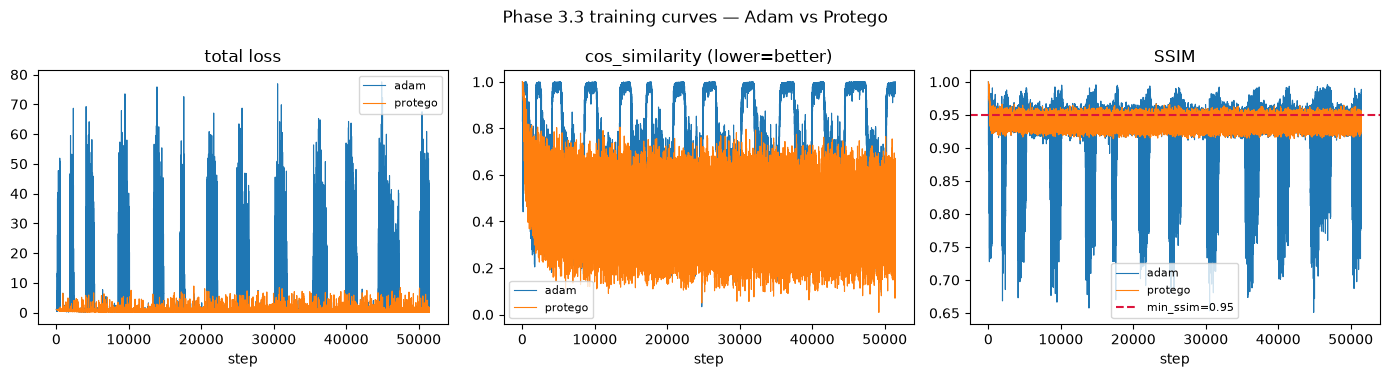

,optimizer,loss_tail,cos_tail,ssim_tail,final_cos,final_ssim
0,adam,8.600270,0.989504,0.897113,0.998567,0.983868
1,protego,0.475309,0.408667,0.939475,0.352165,0.941258


In [3]:
logs = {}
for name, b in runs.items():
    logs[name] = pd.read_csv(b["metrics_dir"] / "train_log.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for name, df in logs.items():
    axes[0].plot(df["step"], df["loss"], lw=0.8, label=name)
    axes[1].plot(df["step"], df["cos_similarity"], lw=0.8, label=name)
    axes[2].plot(df["step"], df["ssim"], lw=0.8, label=name)

axes[0].set_title("total loss")
axes[1].set_title("cos_similarity (lower=better)")
axes[2].set_title("SSIM")
axes[2].axhline(min_ssim, color="crimson", ls="--", label=f"min_ssim={min_ssim}")
for ax in axes:
    ax.set_xlabel("step")
    ax.legend(fontsize=8)
fig.suptitle("Phase 3.3 training curves — Adam vs Protego", fontsize=12)
plt.tight_layout()
plt.show()

cmp_rows = []
for name, df in logs.items():
    tail = df.tail(100)
    cmp_rows.append({
        "optimizer": name,
        "loss_tail": float(tail["loss"].mean()),
        "cos_tail": float(tail["cos_similarity"].mean()),
        "ssim_tail": float(tail["ssim"].mean()),
        "final_cos": runs[name]["summary"].get("final_cos_similarity"),
        "final_ssim": runs[name]["summary"].get("final_ssim"),
    })
display(pd.DataFrame(cmp_rows))

## 3. Footprint espacial (ambos)

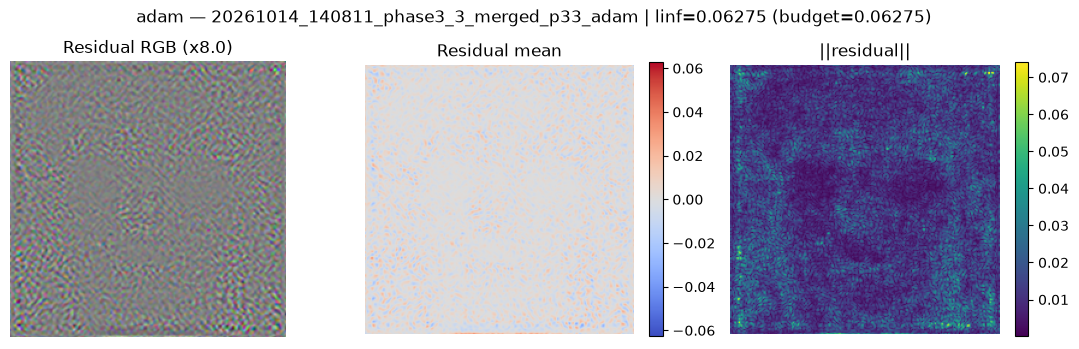

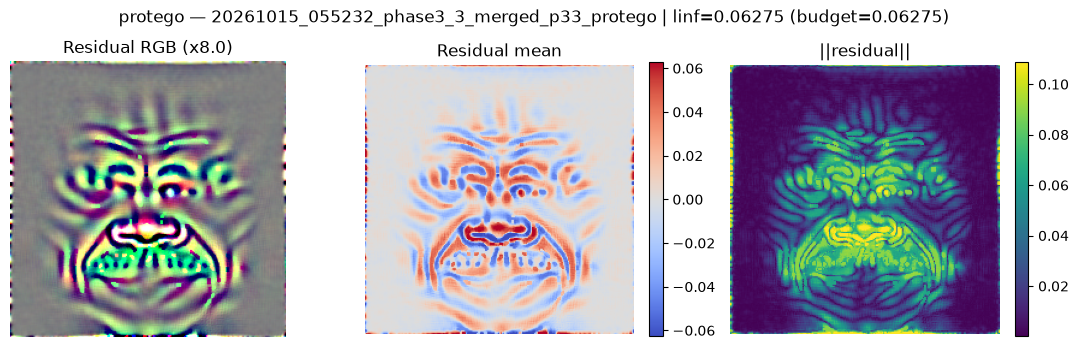

In [4]:
@torch.no_grad()
def show_footprint(module: DTCWTMetaMaskModule, title: str, epsilon: float, img_size: int = 224):
    gray = torch.full((1, 3, img_size, img_size), 0.5, device=DEVICE)
    recon = module(gray)
    prot, residual = apply_linf_budget(recon, gray, epsilon)
    residual = residual[0].detach().cpu()
    res_rgb = residual.permute(1, 2, 0).numpy()
    amp = min(10.0, 0.5 / (residual.abs().max().item() + 1e-8))

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    axes[0].imshow(np.clip(res_rgb * amp + 0.5, 0, 1))
    axes[0].set_title(f"Residual RGB (x{amp:.1f})")
    axes[0].axis("off")
    res_mean = residual.mean(dim=0).numpy()
    lim = max(float(res_mean.std() * 3), epsilon)
    im1 = axes[1].imshow(res_mean, cmap="coolwarm", vmin=-lim, vmax=lim)
    axes[1].set_title("Residual mean")
    axes[1].axis("off")
    fig.colorbar(im1, ax=axes[1], fraction=0.046)
    mag_map = residual.norm(dim=0).numpy()
    im2 = axes[2].imshow(mag_map, cmap="viridis")
    axes[2].set_title("||residual||")
    axes[2].axis("off")
    fig.colorbar(im2, ax=axes[2], fraction=0.046)
    fig.suptitle(f"{title} | linf={residual.abs().max():.5f} (budget={epsilon:.5f})")
    plt.tight_layout()
    plt.show()


for name, mod in mask_mods.items():
    show_footprint(mod, f"{name} — {runs[name]['run_id']}", epsilon, img_size)

## 4. Antes / depois (3 faces) — lado a lado

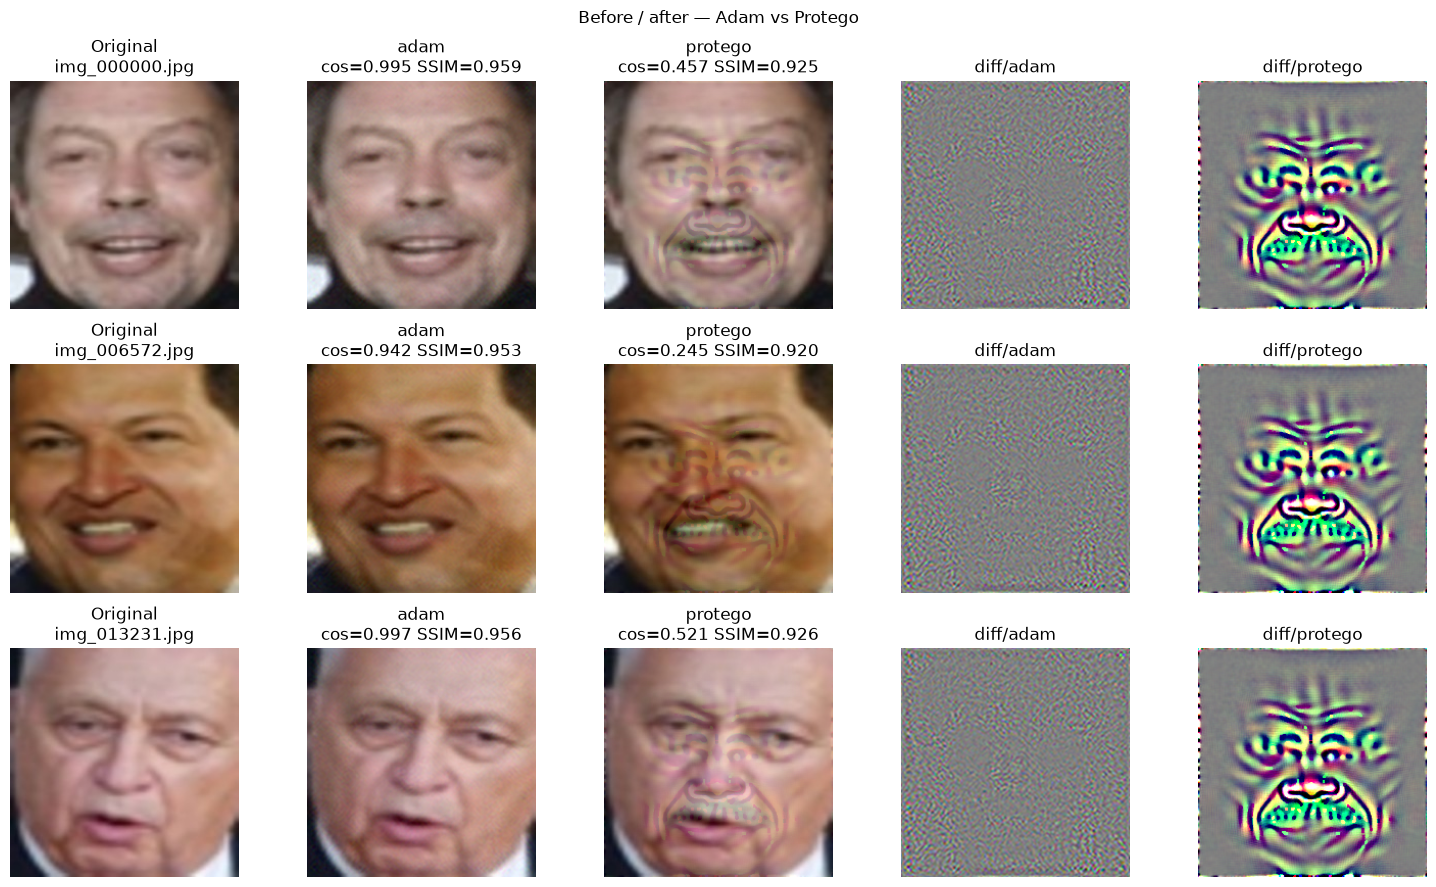

,optimizer,image,cos_similarity,ssim,linf_pixel
0,adam,img_000000.jpg,0.994891,0.958981,0.062745
1,adam,img_006572.jpg,0.942096,0.952712,0.062745
2,adam,img_013231.jpg,0.996803,0.956097,0.062745
3,protego,img_000000.jpg,0.457092,0.925076,0.062745
4,protego,img_006572.jpg,0.244546,0.919519,0.062745
5,protego,img_013231.jpg,0.520611,0.926214,0.062745


In [5]:
fr = FR(model_name=fr_name, device=DEVICE)
fr.fr_model.model.eval()
for p in fr.fr_model.model.parameters():
    p.requires_grad_(False)

split_dir = resolve_split_dir("lfw_frontal", "test")
all_paths = list_image_paths(split_dir)
idxs = np.linspace(0, len(all_paths) - 1, num=N_IMAGES, dtype=int)
paths = [all_paths[i] for i in idxs]
imgs = load_imgs(img_paths=paths, img_sz=img_size, drange=1, device=DEVICE)


def protect_and_metrics(module):
    with torch.no_grad():
        recon = module(imgs)
        protected, residual = apply_linf_budget(recon, imgs, epsilon)
        feat_orig = F.normalize(fr(imgs), p=2, dim=1)
        feat_prot = F.normalize(fr(protected), p=2, dim=1)
        cos_sim = (feat_orig * feat_prot).sum(dim=1)
        ssims = np.array([
            float(calc_ssim(protected[i : i + 1], imgs[i : i + 1], data_range=1.0, size_average=True).cpu())
            for i in range(N_IMAGES)
        ])
    return protected, residual, cos_sim, ssims


results = {name: protect_and_metrics(mod) for name, mod in mask_mods.items()}


def to_np_img(t: torch.Tensor) -> np.ndarray:
    return t.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()


fig, axes = plt.subplots(N_IMAGES, 5, figsize=(15, 3.0 * N_IMAGES))
if N_IMAGES == 1:
    axes = np.expand_dims(axes, 0)

for i in range(N_IMAGES):
    orig = to_np_img(imgs[i])
    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"Original\n{Path(paths[i]).name}")
    axes[i, 0].axis("off")
    for j, name in enumerate(("adam", "protego")):
        prot, residual, cos_sim, ssims = results[name]
        axes[i, 1 + j].imshow(to_np_img(prot[i]))
        axes[i, 1 + j].set_title(
            f"{name}\ncos={cos_sim[i].item():.3f} SSIM={ssims[i]:.3f}"
        )
        axes[i, 1 + j].axis("off")
        diff = np.clip((to_np_img(prot[i]) - orig) / (epsilon + 1e-8) * 0.5 + 0.5, 0, 1)
        axes[i, 3 + j].imshow(diff)
        axes[i, 3 + j].set_title(f"diff/{name}")
        axes[i, 3 + j].axis("off")

fig.suptitle("Before / after — Adam vs Protego", fontsize=12)
plt.tight_layout()
plt.show()

rows = []
for name in ("adam", "protego"):
    _prot, residual, cos_sim, ssims = results[name]
    for i, p in enumerate(paths):
        rows.append({
            "optimizer": name,
            "image": Path(p).name,
            "cos_similarity": float(cos_sim[i]),
            "ssim": float(ssims[i]),
            "linf_pixel": float(residual[i].abs().max()),
        })
display(pd.DataFrame(rows))

## 5. Eval em lote (LFW test ∪ CelebA holdout)

Regenere o split com o mesmo `data_seed` / `celeba_train_frac` do treino.

split_stats: {'n_lfw_train': 8226, 'n_lfw_test': 2029, 'n_celeba_total': 24722, 'n_celeba_train': 12361, 'n_celeba_eval': 12361, 'n_train_total': 20587, 'n_eval_total': 14390}
Evaluating 200/14390 eval images | batch=16 fr=ir50_arcface_casia
  [adam] 16/200
  [adam] 32/200
  [adam] 48/200
  [adam] 64/200
  [adam] 80/200
  [adam] 96/200
  [adam] 112/200
  [adam] 128/200
  [adam] 144/200
  [adam] 160/200
  [adam] 176/200
  [adam] 192/200
  [adam] 200/200
  [protego] 16/200
  [protego] 32/200
  [protego] 48/200
  [protego] 64/200
  [protego] 80/200
  [protego] 96/200
  [protego] 112/200
  [protego] 128/200
  [protego] 144/200
  [protego] 160/200
  [protego] 176/200
  [protego] 192/200
  [protego] 200/200


,optimizer,n,cos_mean,cos_median,ssim_mean,frac_ssim_ok,linf_mean
0,adam,200,0.997673,0.998120,0.969737,0.990,0.062745
1,protego,200,0.283697,0.267714,0.941117,0.145,0.062745


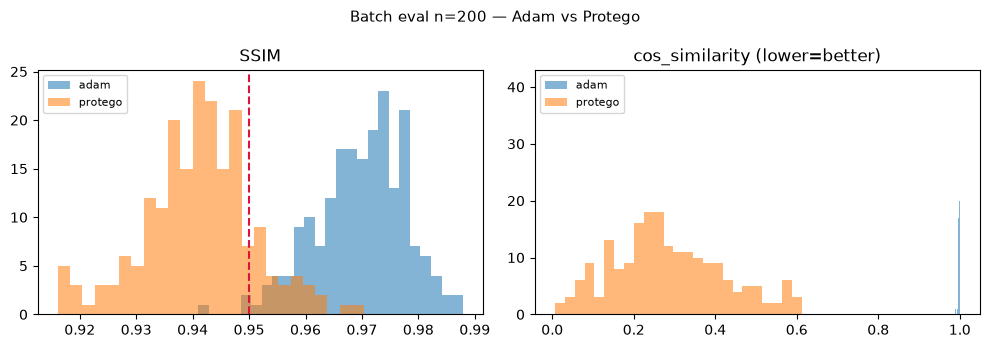

In [6]:
_train, eval_paths_all, split_stats = build_merged_frac_split(
    celeba_train_frac=celeba_frac, data_seed=data_seed
)
print("split_stats:", split_stats)
n_avail = len(eval_paths_all)
n_use = min(N_EVAL, n_avail)
eval_idxs = np.linspace(0, n_avail - 1, num=n_use, dtype=int)
eval_paths = [eval_paths_all[i] for i in eval_idxs]
print(f"Evaluating {n_use}/{n_avail} eval images | batch={EVAL_BATCH} fr={fr_name}")


def eval_batch(module, label: str) -> pd.DataFrame:
    rows_eval = []
    with torch.no_grad():
        for start in range(0, n_use, EVAL_BATCH):
            batch_paths = eval_paths[start : start + EVAL_BATCH]
            batch = load_imgs(img_paths=batch_paths, img_sz=img_size, drange=1, device=DEVICE)
            recon = module(batch)
            prot, res = apply_linf_budget(recon, batch, epsilon)
            feat_o = F.normalize(fr(batch), p=2, dim=1)
            feat_p = F.normalize(fr(prot), p=2, dim=1)
            sim = (feat_o * feat_p).sum(dim=1)
            for i, p in enumerate(batch_paths):
                ssim_i = float(
                    calc_ssim(prot[i : i + 1], batch[i : i + 1], data_range=1.0, size_average=True).cpu()
                )
                rows_eval.append({
                    "optimizer": label,
                    "image": Path(p).name,
                    "cos_similarity": float(sim[i].cpu()),
                    "ssim": ssim_i,
                    "linf_pixel": float(res[i].abs().max().cpu()),
                })
            print(f"  [{label}] {min(start + EVAL_BATCH, n_use)}/{n_use}")
    return pd.DataFrame(rows_eval)


dfs = [eval_batch(mask_mods[name], name) for name in ("adam", "protego")]
df_eval = pd.concat(dfs, ignore_index=True)

summary_rows = []
for name, g in df_eval.groupby("optimizer"):
    summary_rows.append({
        "optimizer": name,
        "n": len(g),
        "cos_mean": float(g["cos_similarity"].mean()),
        "cos_median": float(g["cos_similarity"].median()),
        "ssim_mean": float(g["ssim"].mean()),
        "frac_ssim_ok": float((g["ssim"] >= min_ssim).mean()),
        "linf_mean": float(g["linf_pixel"].mean()),
    })
display(pd.DataFrame(summary_rows))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, g in df_eval.groupby("optimizer"):
    axes[0].hist(g["ssim"], bins=25, alpha=0.55, label=name)
    axes[1].hist(g["cos_similarity"], bins=25, alpha=0.55, label=name)
axes[0].axvline(min_ssim, color="crimson", ls="--")
axes[0].set_title("SSIM")
axes[1].set_title("cos_similarity (lower=better)")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle(f"Batch eval n={n_use} — Adam vs Protego", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Eval ampliado — só Protego (sign-SGD)

Conjunto **não visto no treino**:
- todas as imagens de `lfw_frontal/faces_test`;
- o **mesmo número** de imagens do holdout CelebA (complemento de `celeba_train_frac`, amostradas com `data_seed`).

Reporta: `% cos < 0.5`, cos médio, SSIM médio, LPIPS médio (Alex) e tempo de execução.

Large eval (Protego only): n_lfw_test=2029 + n_celeba=2029 = 4058 | batch=16 | fr=ir50_arcface_casia
split: celeba_frac=0.5 data_seed=42 | celeba_holdout_pool=12361 | min_ssim=0.95
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/home/dcarvalho/dtcwt_mask_optmization/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/dcarvalho/dtcwt_mask_optmization/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /home/dcarvalho/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 86.8MB/s] 


Loading model from: /home/dcarvalho/dtcwt_mask_optmization/.venv/lib/python3.12/site-packages/lpips/weights/v0.1/alex.pth
  processed 128/4058
  processed 256/4058
  processed 384/4058
  processed 512/4058
  processed 640/4058
  processed 768/4058
  processed 896/4058
  processed 1024/4058
  processed 1152/4058
  processed 1280/4058
  processed 1408/4058
  processed 1536/4058
  processed 1664/4058
  processed 1792/4058
  processed 1920/4058
  processed 2048/4058
  processed 2176/4058
  processed 2304/4058
  processed 2432/4058
  processed 2560/4058
  processed 2688/4058
  processed 2816/4058
  processed 2944/4058
  processed 3072/4058
  processed 3200/4058
  processed 3328/4058
  processed 3456/4058
  processed 3584/4058
  processed 3712/4058
  processed 3840/4058
  processed 3968/4058
  processed 4058/4058


,value
optimizer,protego (sign-SGD)
n_total,4058
n_lfw_test,2029
n_celeba_holdout,2029
cos_thresh,0.5
pct_cos_below_thresh,84.056185
cos_mean,0.327432
cos_median,0.308489
ssim_mean,0.935191
lpips_mean,0.117649



Por fonte:


,source,n,cos_mean,pct_cos_lt_0_5,ssim_mean,lpips_mean
0,celeba_holdout,2029,0.297878,90.290784,0.942981,0.058912
1,lfw_test,2029,0.356986,77.821587,0.927402,0.176387



=== Protego large eval ===
  n=4058 (LFW test=2029 + CelebA=2029)
  pct cos < 0.5: 84.06%
  cos_mean=0.3274 | ssim_mean=0.9352 | lpips_mean=0.1176
  elapsed=96.4s (42.09 img/s)


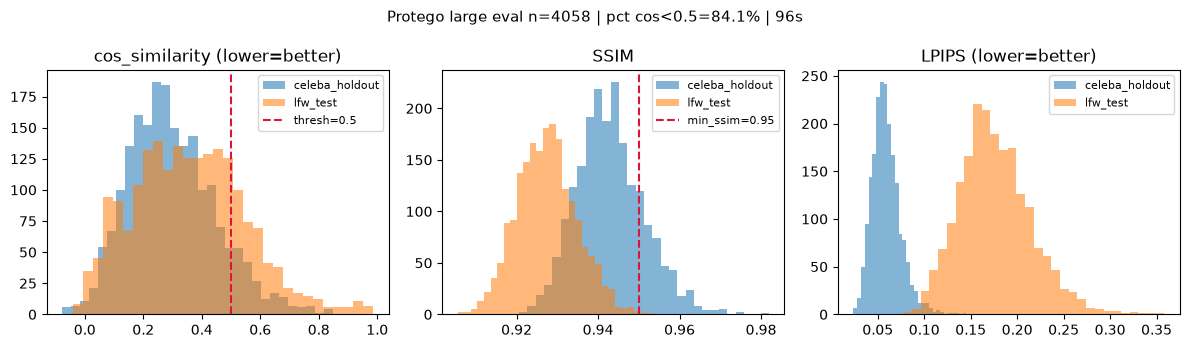

In [7]:
import time

import lpips

COS_THRESH = 0.5
LARGE_EVAL_BATCH = EVAL_BATCH

# Rebuild Phase 3.3 split so LFW test + CelebA holdout match training.
_train_full, _eval_full, split_stats_full = build_merged_frac_split(
    celeba_train_frac=celeba_frac, data_seed=data_seed
)
lfw_test_paths = list_image_paths(resolve_split_dir("lfw_frontal", "test"))
# CelebA holdout = eval paths that are not LFW test (same seed/frac as train).
lfw_test_set = set(lfw_test_paths)
celeba_holdout = [p for p in _eval_full if p not in lfw_test_set]
n_lfw = len(lfw_test_paths)
assert n_lfw > 0, "LFW faces_test is empty"
assert len(celeba_holdout) >= n_lfw, (
    f"CelebA holdout ({len(celeba_holdout)}) < LFW test ({n_lfw}); "
    f"lower celeba_train_frac or check split"
)
rng_eval = np.random.default_rng(data_seed)
celeba_sample = list(celeba_holdout)
rng_eval.shuffle(celeba_sample)
celeba_sample = celeba_sample[:n_lfw]

large_paths = list(lfw_test_paths) + list(celeba_sample)
large_sources = (["lfw_test"] * n_lfw) + (["celeba_holdout"] * n_lfw)
print(
    f"Large eval (Protego only): n_lfw_test={n_lfw} + n_celeba={len(celeba_sample)} "
    f"= {len(large_paths)} | batch={LARGE_EVAL_BATCH} | fr={fr_name}"
)
print(
    f"split: celeba_frac={celeba_frac} data_seed={data_seed} | "
    f"celeba_holdout_pool={len(celeba_holdout)} | min_ssim={min_ssim}"
)

lpips_fn = lpips.LPIPS(net="alex").to(DEVICE)
lpips_fn.eval()
for p in lpips_fn.parameters():
    p.requires_grad_(False)


def _lpips_batch(orig: torch.Tensor, prot: torch.Tensor) -> torch.Tensor:
    """LPIPS expects roughly [-1, 1]. Returns per-image scores (B,)."""
    o = orig * 2.0 - 1.0
    p = prot * 2.0 - 1.0
    return lpips_fn(o, p).view(-1)


module = mask_mods["protego"]
rows_large = []
t0 = time.perf_counter()
with torch.no_grad():
    for start in range(0, len(large_paths), LARGE_EVAL_BATCH):
        batch_paths = large_paths[start : start + LARGE_EVAL_BATCH]
        batch_src = large_sources[start : start + LARGE_EVAL_BATCH]
        batch = load_imgs(img_paths=batch_paths, img_sz=img_size, drange=1, device=DEVICE)
        recon = module(batch)
        prot, res = apply_linf_budget(recon, batch, epsilon)
        feat_o = F.normalize(fr(batch), p=2, dim=1)
        feat_p = F.normalize(fr(prot), p=2, dim=1)
        sim = (feat_o * feat_p).sum(dim=1)
        lp = _lpips_batch(batch, prot)
        for i, pth in enumerate(batch_paths):
            ssim_i = float(
                calc_ssim(
                    prot[i : i + 1], batch[i : i + 1], data_range=1.0, size_average=True
                ).cpu()
            )
            rows_large.append({
                "source": batch_src[i],
                "image": Path(pth).name,
                "cos_similarity": float(sim[i].cpu()),
                "ssim": ssim_i,
                "lpips": float(lp[i].cpu()),
                "linf_pixel": float(res[i].abs().max().cpu()),
            })
        done = min(start + LARGE_EVAL_BATCH, len(large_paths))
        if done % (LARGE_EVAL_BATCH * 8) == 0 or done == len(large_paths):
            print(f"  processed {done}/{len(large_paths)}")
elapsed_s = time.perf_counter() - t0

df_large = pd.DataFrame(rows_large)
cos = df_large["cos_similarity"].to_numpy()
frac_below = float((cos < COS_THRESH).mean())

summary_large = {
    "optimizer": "protego (sign-SGD)",
    "n_total": int(len(df_large)),
    "n_lfw_test": int((df_large["source"] == "lfw_test").sum()),
    "n_celeba_holdout": int((df_large["source"] == "celeba_holdout").sum()),
    "cos_thresh": COS_THRESH,
    "pct_cos_below_thresh": 100.0 * frac_below,
    "cos_mean": float(cos.mean()),
    "cos_median": float(np.median(cos)),
    "ssim_mean": float(df_large["ssim"].mean()),
    "lpips_mean": float(df_large["lpips"].mean()),
    "frac_ssim_ge_min": float((df_large["ssim"] >= min_ssim).mean()),
    "elapsed_seconds": float(elapsed_s),
    "images_per_second": float(len(df_large) / max(elapsed_s, 1e-9)),
}
display(pd.DataFrame([summary_large]).T.rename(columns={0: "value"}))

# Breakdown by source
by_src = (
    df_large.groupby("source")
    .agg(
        n=("cos_similarity", "size"),
        cos_mean=("cos_similarity", "mean"),
        pct_cos_lt_0_5=("cos_similarity", lambda s: 100.0 * float((s < COS_THRESH).mean())),
        ssim_mean=("ssim", "mean"),
        lpips_mean=("lpips", "mean"),
    )
    .reset_index()
)
print("\nPor fonte:")
display(by_src)

print(
    f"\n=== Protego large eval ===\n"
    f"  n={summary_large['n_total']} "
    f"(LFW test={summary_large['n_lfw_test']} + CelebA={summary_large['n_celeba_holdout']})\n"
    f"  pct cos < {COS_THRESH}: {summary_large['pct_cos_below_thresh']:.2f}%\n"
    f"  cos_mean={summary_large['cos_mean']:.4f} | ssim_mean={summary_large['ssim_mean']:.4f} "
    f"| lpips_mean={summary_large['lpips_mean']:.4f}\n"
    f"  elapsed={summary_large['elapsed_seconds']:.1f}s "
    f"({summary_large['images_per_second']:.2f} img/s)"
)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for src, g in df_large.groupby("source"):
    axes[0].hist(g["cos_similarity"], bins=30, alpha=0.55, label=src)
    axes[1].hist(g["ssim"], bins=30, alpha=0.55, label=src)
    axes[2].hist(g["lpips"], bins=30, alpha=0.55, label=src)
axes[0].axvline(COS_THRESH, color="crimson", ls="--", label=f"thresh={COS_THRESH}")
axes[1].axvline(min_ssim, color="crimson", ls="--", label=f"min_ssim={min_ssim}")
axes[0].set_title("cos_similarity (lower=better)")
axes[1].set_title("SSIM")
axes[2].set_title("LPIPS (lower=better)")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle(
    f"Protego large eval n={len(df_large)} | "
    f"pct cos<{COS_THRESH}={summary_large['pct_cos_below_thresh']:.1f}% | "
    f"{summary_large['elapsed_seconds']:.0f}s",
    fontsize=11,
)
plt.tight_layout()
plt.show()